In [1]:
# Install the required open-source libraries
!pip -q install tensorflow pandas numpy scikit-learn matplotlib scipy

In [2]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")

# Make results more reproducible
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("Environment ready!")

TensorFlow: 2.21.0
Pandas: 2.2.3
NumPy: 2.1.3
SciPy: 1.16.3
Environment ready!


In [4]:
from google.colab import files

uploaded = files.upload()


Saving Stock_Market_Dataset_Kaggle.csv to Stock_Market_Dataset_Kaggle.csv


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

# Load your uploaded CSV
df = pd.read_csv("Stock_Market_Dataset_Kaggle.csv")

# Clean column names and convert data types
df.columns = df.columns.str.strip()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Close"] = pd.to_numeric(df["Close"], errors="coerce")

# Remove invalid records and duplicate dates
df = df.dropna(subset=["Date", "Close"])
df = df[df["Close"] > 0]
df = df.sort_values("Date")
df = df.drop_duplicates(subset=["Date"], keep="last")
df = df.tail(2000).reset_index(drop=True)

assert len(df) == 2000, "Expected 2,000 valid records."

print("Dataset shape:", df.shape)
print("Stock ticker:", df["Ticker"].iloc[0])
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())
display(df.head())

Dataset shape: (2000, 8)
Stock ticker: SAMPLE
First date: 2018-01-02 00:00:00
Last date: 2025-09-01 00:00:00


,Date,Ticker,Open,High,Low,Close,Adj Close,Volume
0,2018-01-02,SAMPLE,99.82,101.84,98.47,100.48,100.48,5664869
1,2018-01-03,SAMPLE,100.22,101.96,97.23,98.95,98.95,5376221
2,2018-01-04,SAMPLE,99.12,101.46,97.77,100.10,100.10,3476715
3,2018-01-05,SAMPLE,100.20,104.13,97.65,101.55,101.55,6299750
4,2018-01-08,SAMPLE,100.97,103.05,96.61,98.64,98.64,5987473


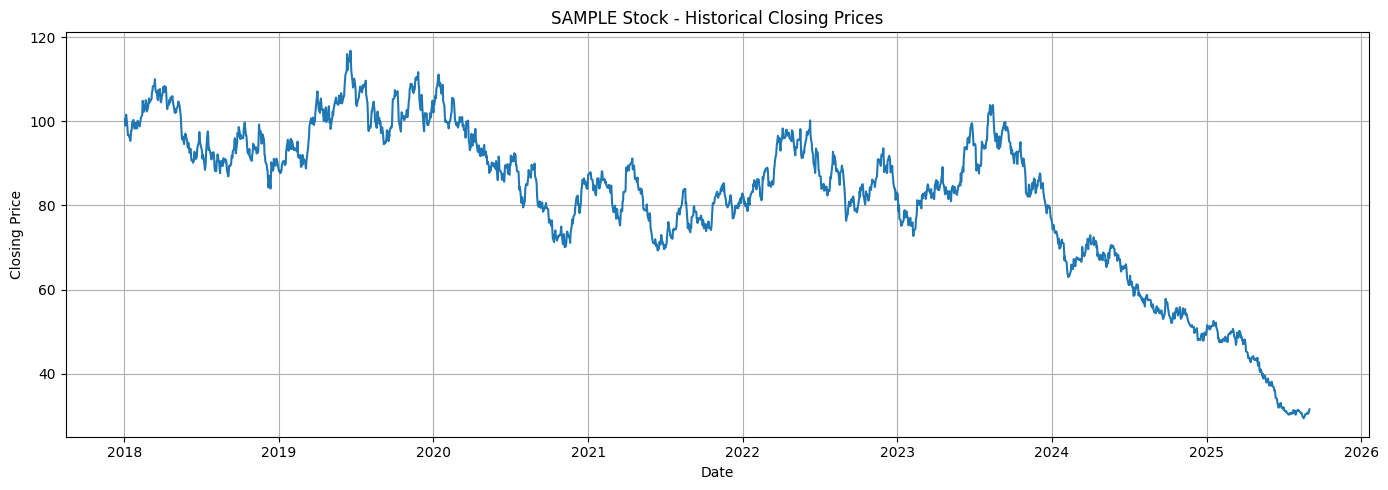

In [7]:
plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["Close"])
plt.title("SAMPLE Stock - Historical Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
split_index = int(len(df) * 0.80)

prices = df["Close"].values.reshape(-1, 1)

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(prices[:split_index])

scaled_prices = scaler.transform(prices)

print("Training records:", split_index)
print("Testing records:", len(df) - split_index)

Training records: 1600
Testing records: 400


In [9]:
WINDOW_SIZE = 60

X, y, target_indices = [], [], []

for i in range(WINDOW_SIZE, len(scaled_prices)):
    X.append(scaled_prices[i-WINDOW_SIZE:i, 0])
    y.append(scaled_prices[i, 0])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train = X[train_mask].reshape(-1, WINDOW_SIZE, 1)
y_train = y[train_mask]

X_test = X[test_mask].reshape(-1, WINDOW_SIZE, 1)
y_test = y[test_mask]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (1540, 60, 1)
X_test: (400, 60, 1)


In [10]:
model = Sequential([
    tf.keras.Input(shape=(60, 1)),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mean_squared_error",
    metrics=["mean_absolute_error"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,857 (116.63 KB)

 Trainable params: 29,857 (116.63 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - loss: 0.0656 - mean_absolute_error: 0.1936 - val_loss: 0.0196 - val_mean_absolute_error: 0.1156
Epoch 2/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 50ms/step - loss: 0.0235 - mean_absolute_error: 0.1233 - val_loss: 0.0213 - val_mean_absolute_error: 0.1253
Epoch 3/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step - loss: 0.0208 - mean_absolute_error: 0.1144 - val_loss: 0.0222 - val_mean_absolute_error: 0.1281
Epoch 4/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 4s 101ms/step - loss: 0.0236 - mean_absolute_error: 0.1241 - val_loss: 0.0249 - val_mean_absolute_error: 0.1350
Epoch 5/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.0248 - mean_absolute_error: 0.1283 - val_loss: 0.0254 - val_mean_absolute_error: 0.1363
Epoch 6/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - loss: 0.0254 - mean_absolute_error: 0.1297 - val_loss: 0.0233 - val_mean_absolute_error: 0.1303
Epoch 7/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 51ms/step - loss: 0.0220 - mean_absolute_error: 0.1207 - val_los

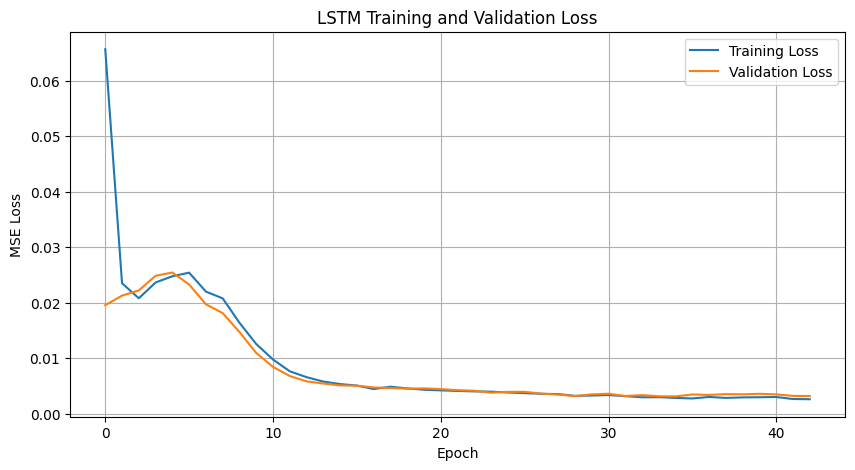

In [12]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(True)
plt.show()

In [13]:
predicted_scaled = model.predict(X_test, verbose=0)

predicted_prices = scaler.inverse_transform(
    predicted_scaled
).flatten()

actual_prices = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

mae = mean_absolute_error(actual_prices, predicted_prices)
rmse = np.sqrt(mean_squared_error(actual_prices, predicted_prices))

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

MAE: 18.0154
RMSE: 20.9048


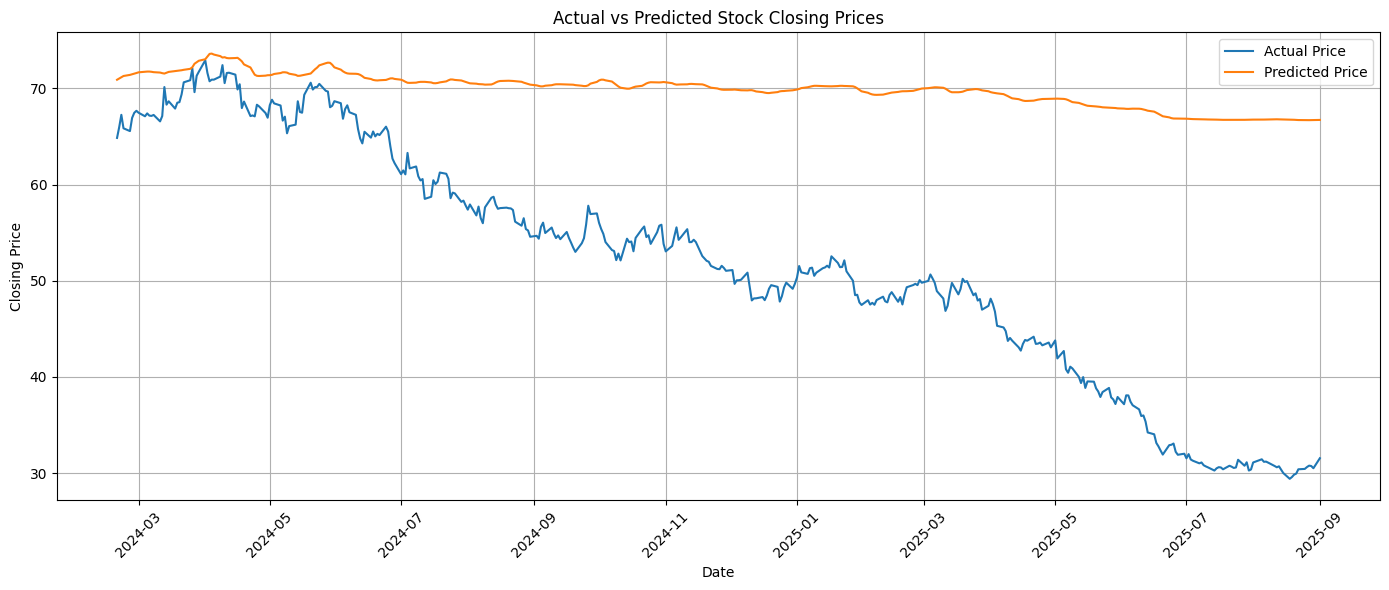

,Date,Actual_Close,Predicted_Close
0,2024-02-20,64.85,70.898453
1,2024-02-21,65.97,71.029587
2,2024-02-22,67.25,71.153046
3,2024-02-23,65.85,71.289169
4,2024-02-26,65.56,71.403961
5,2024-02-27,66.93,71.466560
6,2024-02-28,67.46,71.527359
7,2024-02-29,67.67,71.598877
8,2024-03-01,67.47,71.670639
9,2024-03-04,67.10,71.727867


In [14]:
test_dates = df["Date"].iloc[
    target_indices[test_mask]
].reset_index(drop=True)

results = pd.DataFrame({
    "Date": test_dates,
    "Actual_Close": actual_prices,
    "Predicted_Close": predicted_prices
})

plt.figure(figsize=(14, 6))
plt.plot(test_dates, actual_prices, label="Actual Price")
plt.plot(test_dates, predicted_prices, label="Predicted Price")
plt.title("Actual vs Predicted Stock Closing Prices")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(results.head(10))

In [15]:
current_window = scaled_prices[-60:, 0].tolist()
future_scaled = []

for _ in range(5):
    input_data = np.array(
        current_window[-60:]
    ).reshape(1, 60, 1)

    next_price = float(model.predict(input_data, verbose=0)[0, 0])

    future_scaled.append(next_price)
    current_window.append(next_price)

future_prices = scaler.inverse_transform(
    np.array(future_scaled).reshape(-1, 1)
).flatten()

last_date = df["Date"].iloc[-1]
future_dates = pd.bdate_range(
    start=last_date + pd.Timedelta(days=1),
    periods=5
)

future_results = pd.DataFrame({
    "Forecast_Date": future_dates,
    "Predicted_Close": future_prices
})

display(future_results.round(2))

,Forecast_Date,Predicted_Close
0,2025-09-02,66.73
1,2025-09-03,67.48
2,2025-09-04,69.09
3,2025-09-05,71.08
4,2025-09-08,73.10


In [16]:
model.save("stock_lstm_model.keras")
results.to_csv("test_predictions.csv", index=False)
future_results.to_csv("future_forecast.csv", index=False)

print("Model and prediction files saved successfully!")

Model and prediction files saved successfully!
